# Healthcare Appointment No-Shows: Who Shows Up and Who Doesn't?

> **Data source & credit:** this dataset is courtesy of **[Kaggle](https://www.kaggle.com/)**. It comes from the *Medical Appointment No Shows* dataset (public appointment records from Vitória, Espírito Santo, Brazil, 2016) originally published on Kaggle by Joni Hoppen / Aquarela Analytics: <https://www.kaggle.com/datasets/joniarroba/noshowappointments>. The file used here, `healthcare_noshows.csv`, is a cleaned version of that data (outcome recoded as `Showed_up`, with a precomputed `Date.diff` lead-time column). All credit for data collection and publication goes to the original authors and Kaggle; the analysis and conclusions in this notebook are our own.

This notebook looks at about 107k medical appointments (Vitória, Brazil, Apr–Jun 2016) and compares patients who **showed up** with those who **didn't**.

**Libraries:** pandas, NumPy, matplotlib, seaborn, SciPy (statistical tests), scikit-learn (predictive model).

**Contents**
1. Load and clean the data
2. Overall show rate
3. Demographics: age and gender
4. Health conditions and welfare (Scholarship)
5. Lead time (days between booking and appointment)
6. SMS reminders, and why the raw numbers mislead
7. Day of week
8. Neighbourhood
9. Patient history: repeat no-shows
10. Statistical significance summary
11. Predictive model (logistic regression and random forest)
12. Key takeaways (first pass)
13. Deep dive: routine vs. need-driven bookings for kids and seniors (SMS effects, repeat missers)
14. Full logistic regression with odds ratios and predicted rates
15. Segmentation: clustering vs. PCA vs. supervised models
16. **Final recommendation: 3-level decision tree risk tiers**

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report, RocCurveDisplay
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=RuntimeWarning)  # spurious matmul warnings from macOS Accelerate BLAS
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.3f}".format)
SHOW_COLORS = {"Showed up": "#2a9d8f", "No-show": "#e76f51"}

## 1. Load and clean the data

In [2]:
df = pd.read_csv("healthcare_noshows.csv", parse_dates=["ScheduledDay", "AppointmentDay"])
print(df.shape)
df.head()

(106987, 15)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,Showed_up,Date.diff
0,29872499824296.000,5642903,F,2016-04-29,2016-04-29,62,JARDIM DA PENHA,False,True,False,False,False,False,True,0
1,558997776694438.000,5642503,M,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,False,False,False,False,False,True,0
2,4262962299951.000,5642549,F,2016-04-29,2016-04-29,62,MATA DA PRAIA,False,False,False,False,False,False,True,0
3,867951213174.000,5642828,F,2016-04-29,2016-04-29,8,PONTAL DE CAMBURI,False,False,False,False,False,False,True,0
4,8841186448183.000,5642494,F,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,True,True,False,False,False,True,0


In [3]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Unique patients:", df.PatientId.nunique())
print("Lead time (Date.diff) < 0:", (df["Date.diff"] < 0).sum())
print("Age < 0:", (df.Age < 0).sum(), "| Age > 100:", (df.Age > 100).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106987 entries, 0 to 106986
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   PatientId       106987 non-null  float64       
 1   AppointmentID   106987 non-null  int64         
 2   Gender          106987 non-null  object        
 3   ScheduledDay    106987 non-null  datetime64[ns]
 4   AppointmentDay  106987 non-null  datetime64[ns]
 5   Age             106987 non-null  int64         
 6   Neighbourhood   106987 non-null  object        
 7   Scholarship     106987 non-null  bool          
 8   Hipertension    106987 non-null  bool          
 9   Diabetes        106987 non-null  bool          
 10  Alcoholism      106987 non-null  bool          
 11  Handcap         106987 non-null  bool          
 12  SMS_received    106987 non-null  bool          
 13  Showed_up       106987 non-null  bool          
 14  Date.diff       106987 non-null  int

A few rows have a **negative lead time** (appointment dated before it was scheduled), which must be data-entry errors, so we drop them.
Then we add some helper columns: age bands, lead-time bands, day of week, and a readable outcome label.

In [4]:
df = df[df["Date.diff"] >= 0].copy()
df = df.rename(columns={"Hipertension": "Hypertension", "Handcap": "Handicap", "Date.diff": "LeadDays"})

df["NoShow"] = (~df.Showed_up).astype(int)
df["Outcome"] = np.where(df.Showed_up, "Showed up", "No-show")
df["AgeGroup"] = pd.cut(df.Age, [-1, 12, 17, 25, 35, 45, 55, 65, 75, 120],
                        labels=["0-12", "13-17", "18-25", "26-35", "36-45", "46-55", "56-65", "66-75", "76+"])
df["LeadBand"] = pd.cut(df.LeadDays, [-1, 0, 2, 7, 14, 30, 60, 200],
                        labels=["Same day", "1-2", "3-7", "8-14", "15-30", "31-60", "60+"])
df["Weekday"] = df.AppointmentDay.dt.day_name()
print(df.shape)

(106982, 20)


## 2. Overall show rate

Outcome
Showed up    85307
No-show      21675
Name: count, dtype: int64 

No-show rate: 20.3%


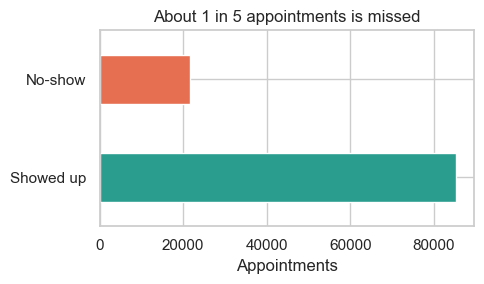

In [5]:
counts = df.Outcome.value_counts()
print(counts, "\n")
print(f"No-show rate: {df.NoShow.mean():.1%}")

fig, ax = plt.subplots(figsize=(5, 3))
counts.plot.barh(ax=ax, color=[SHOW_COLORS[k] for k in counts.index])
ax.set_xlabel("Appointments"); ax.set_ylabel("")
ax.set_title("About 1 in 5 appointments is missed")
plt.tight_layout(); plt.show()

We'll compare every group to this **~20% baseline no-show rate**. A small helper builds the rate table and chart for each factor.

In [6]:
BASE = df.NoShow.mean()

def rate_table(col, data=df):
    t = (data.groupby(col, observed=True)
             .agg(appointments=("NoShow", "size"), no_show_rate=("NoShow", "mean")))
    t["vs_baseline_pp"] = (t.no_show_rate - BASE) * 100
    return t

def plot_rate(col, ax=None, data=df, title=None, horizontal=False, order=None):
    t = rate_table(col, data)
    if order is not None:
        t = t.loc[order]
    ax = ax or plt.gca()
    kind = "barh" if horizontal else "bar"
    getattr(t.no_show_rate.plot, kind)(ax=ax, color="#e76f51")
    line = ax.axvline if horizontal else ax.axhline
    line(BASE, ls="--", color="gray", lw=1, label=f"Overall {BASE:.1%}")
    fmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
    (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(fmt)
    ax.set_title(title or f"No-show rate by {col}")
    ax.set_xlabel("" if not horizontal else "No-show rate")
    ax.set_ylabel("No-show rate" if not horizontal else "")
    ax.legend(loc="best", fontsize=8)
    return t

## 3. Demographics: age and gender

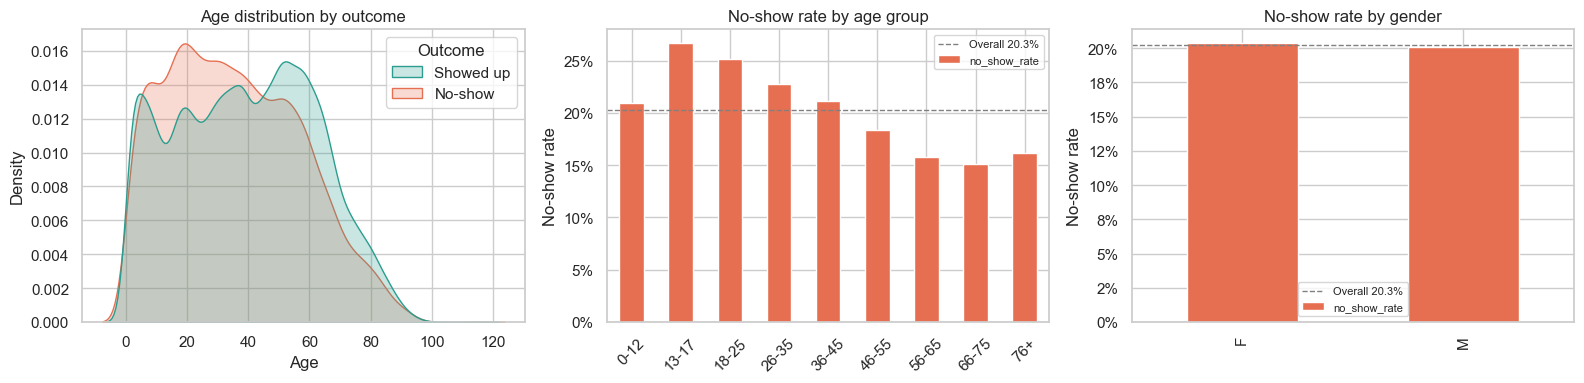

              count   mean    std   min    25%    50%    75%     max
Outcome                                                             
No-show   21675.000 35.330 21.470 1.000 18.000 33.000 52.000 115.000
Showed up 85307.000 39.075 22.650 1.000 20.000 39.000 57.000 115.000


,appointments,no_show_rate,vs_baseline_pp
AgeGroup,,,
0-12,17496,0.210,0.699
13-17,6343,0.266,6.383
18-25,11218,0.251,4.869
26-35,14404,0.228,2.525
36-45,14581,0.211,0.870
46-55,15437,0.184,-1.902
56-65,14203,0.158,-4.510
66-75,7909,0.151,-5.138
76+,5391,0.161,-4.141


,appointments,no_show_rate,vs_baseline_pp
Gender,,,
F,70115,0.204,0.095
M,36867,0.201,-0.180


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.kdeplot(data=df, x="Age", hue="Outcome", common_norm=False, fill=True,
            palette=SHOW_COLORS, ax=axes[0])
axes[0].set_title("Age distribution by outcome")

plot_rate("AgeGroup", ax=axes[1], title="No-show rate by age group")
axes[1].tick_params(axis="x", rotation=45)

plot_rate("Gender", ax=axes[2], title="No-show rate by gender")
plt.tight_layout(); plt.show()

print(df.groupby("Outcome").Age.describe())
display(rate_table("AgeGroup"))
display(rate_table("Gender"))

**What we see:**
- Patients who show up are **older** on average. No-shows peak among **teens and young adults (13–25)** and drop steadily after 45. Patients over 65 have the lowest no-show rates.
- **Gender makes almost no difference.** Women book about twice as many appointments, but men and women miss them at nearly the same rate.

## 4. Health conditions and welfare (Scholarship)

,no_show_if_TRUE,n_TRUE,no_show_if_FALSE,diff_pp
factor,,,,
Scholarship,0.238,10809,0.199,3.922
Hypertension,0.173,21801,0.210,-3.716
Diabetes,0.180,7943,0.204,-2.438
Alcoholism,0.201,3360,0.203,-0.115
Handicap,0.181,2238,0.203,-2.210


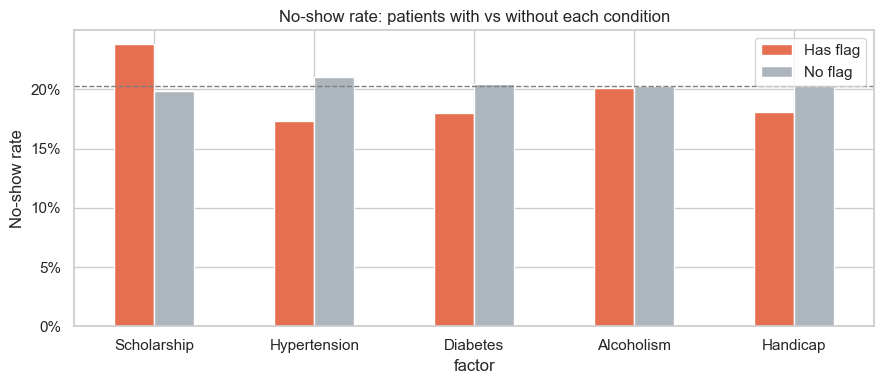

In [8]:
flags = ["Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap"]
rows = []
for f in flags:
    t = df.groupby(f).NoShow.agg(["mean", "size"])
    rows.append({"factor": f,
                 "no_show_if_TRUE": t.loc[True, "mean"], "n_TRUE": t.loc[True, "size"],
                 "no_show_if_FALSE": t.loc[False, "mean"],
                 "diff_pp": (t.loc[True, "mean"] - t.loc[False, "mean"]) * 100})
flag_tbl = pd.DataFrame(rows).set_index("factor")
display(flag_tbl)

long = flag_tbl[["no_show_if_TRUE", "no_show_if_FALSE"]].rename(
    columns={"no_show_if_TRUE": "Has flag", "no_show_if_FALSE": "No flag"})
ax = long.plot.bar(figsize=(9, 4), color=["#e76f51", "#adb5bd"], rot=0)
ax.axhline(BASE, ls="--", color="gray", lw=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("No-show rate: patients with vs without each condition")
ax.set_ylabel("No-show rate"); plt.tight_layout(); plt.show()

**What we see:**
- **Scholarship** (enrolment in Bolsa Família, Brazil's welfare program, so a rough proxy for low income) goes with a **higher** no-show rate.
- **Hypertension and diabetes** go with **lower** no-show rates. These are chronic conditions with regular check-ups, and the patients are older. Age is likely a big part of the story (the model in section 11 controls for it).
- **Alcoholism** and **handicap** make little difference overall.

In [9]:
# Does the chronic-condition effect survive within age groups?
chronic = (df.assign(Chronic=df.Hypertension | df.Diabetes)
             .pivot_table(index="AgeGroup", columns="Chronic", values="NoShow", aggfunc="mean", observed=True))
chronic.columns = ["No chronic condition", "Hypertension/Diabetes"]
display(chronic.style.format("{:.1%}"))

,No chronic condition,Hypertension/Diabetes
AgeGroup,,
0-12,20.9%,32.1%
13-17,26.6%,36.5%
18-25,25.1%,24.6%
26-35,22.8%,22.5%
36-45,21.5%,19.0%
46-55,18.3%,18.5%
56-65,14.9%,16.7%
66-75,14.7%,15.4%
76+,14.1%,17.3%


**Once age is held constant, the chronic-condition effect disappears.** Within most age bands, patients with hypertension or diabetes miss appointments at about the same rate as everyone else, and sometimes slightly more often. The apparent "chronic patients are reliable" effect is really an **age effect**: chronic patients are older, and older patients show up.

## 5. Lead time: days between booking and appointment

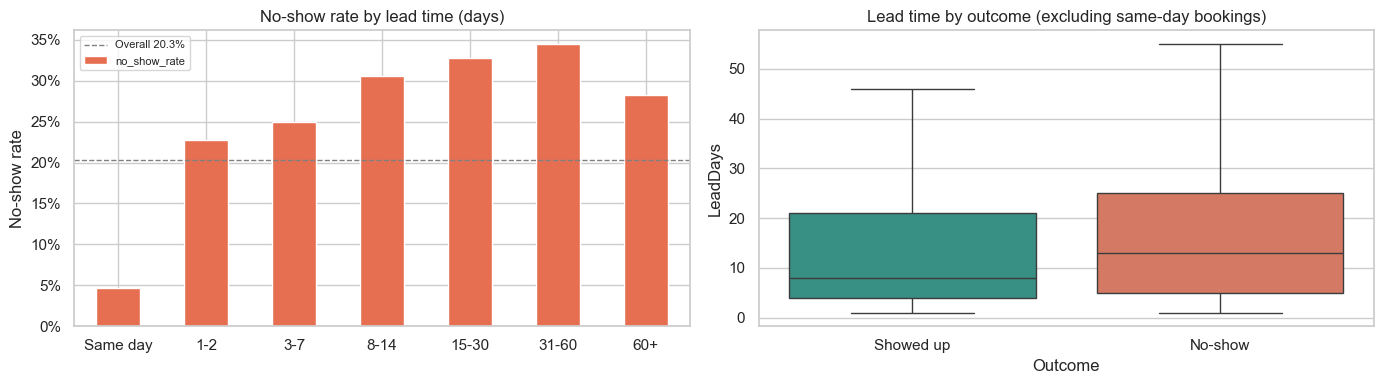

,appointments,no_show_rate,vs_baseline_pp
LeadBand,,,
Same day,37154,0.047,-15.575
1-2,11664,0.228,2.536
3-7,19782,0.249,4.631
8-14,11644,0.305,10.262
15-30,16742,0.327,12.484
31-60,7952,0.344,14.159
60+,2044,0.283,8.017


              count   mean    std   min   25%    50%    75%     max
Outcome                                                            
No-show   21675.000 15.793 16.616 0.000 4.000 11.000 23.000 179.000
Showed up 85307.000  8.738 14.558 0.000 0.000  2.000 12.000 179.000


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
t = plot_rate("LeadBand", ax=axes[0], title="No-show rate by lead time (days)")
axes[0].tick_params(axis="x", rotation=0)

sns.boxplot(data=df[df.LeadDays > 0], x="Outcome", y="LeadDays", hue="Outcome",
            palette=SHOW_COLORS, ax=axes[1], showfliers=False, legend=False)
axes[1].set_title("Lead time by outcome (excluding same-day bookings)")
plt.tight_layout(); plt.show()

display(t)
print(df.groupby("Outcome").LeadDays.describe())

**This is the strongest single signal in the data.**
- **Same-day** appointments are almost always kept (~5% no-show).
- Once there's any gap, the no-show rate jumps to about 23%, then climbs to about 34% for waits of 1–2 months.
- The median lead time for no-shows is several times that of patients who showed up.

## 6. SMS reminders, and why the raw numbers mislead

In [11]:
display(rate_table("SMS_received"))

,appointments,no_show_rate,vs_baseline_pp
SMS_received,,,
False,72397,0.167,-3.537
True,34585,0.277,7.405


On the raw numbers, patients who got an SMS reminder were **more likely** to miss their appointment. That sounds backwards, but it's **confounded by lead time**: reminders only go out for appointments booked several days ahead, and those appointments already have high no-show rates. (No same-day appointment gets an SMS.)

The fair test is to compare SMS vs no SMS **within the same lead-time band**:

SMS_received  False  True 
LeadBand                  
Same day      37154      0
1-2           11664      0
3-7            8409  11373
8-14           4811   6833
15-30          6536  10206
31-60          3099   4853
60+             724   1320 



,No SMS,SMS received,SMS effect (pp)
LeadBand,,,
3-7,26.4%,23.8%,-2.6
8-14,33.9%,28.1%,-5.8
15-30,37.0%,30.0%,-7.0
31-60,38.5%,31.8%,-6.7
60+,33.3%,25.5%,-7.8


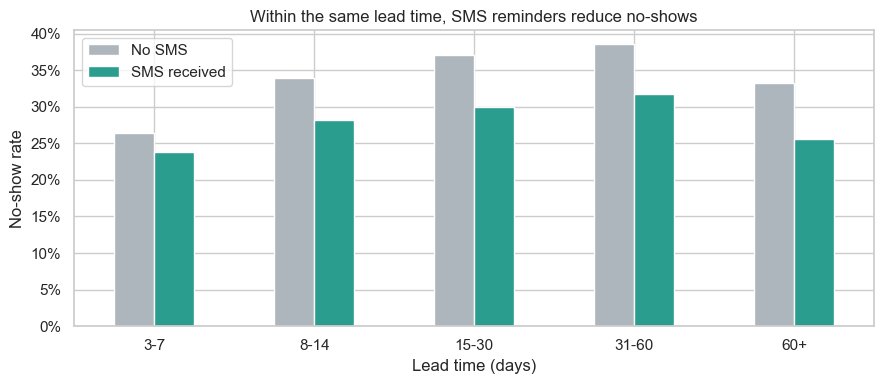

In [12]:
print(pd.crosstab(df.LeadBand, df.SMS_received), "\n")

sms = df[df.LeadDays >= 3].pivot_table(index="LeadBand", columns="SMS_received",
                                       values="NoShow", aggfunc="mean", observed=True)
sms.columns = ["No SMS", "SMS received"]
sms["SMS effect (pp)"] = (sms["SMS received"] - sms["No SMS"]) * 100
display(sms.style.format({"No SMS": "{:.1%}", "SMS received": "{:.1%}", "SMS effect (pp)": "{:+.1f}"}))

ax = sms[["No SMS", "SMS received"]].plot.bar(figsize=(9, 4), color=["#adb5bd", "#2a9d8f"], rot=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Within the same lead time, SMS reminders reduce no-shows")
ax.set_ylabel("No-show rate"); ax.set_xlabel("Lead time (days)")
plt.tight_layout(); plt.show()

**This is a textbook Simpson's paradox.** Within each lead-time band, patients who got a reminder have a **lower** no-show rate than those who didn't. The reminders seem to work. They just get sent to the riskiest appointments.

## 7. Day of week

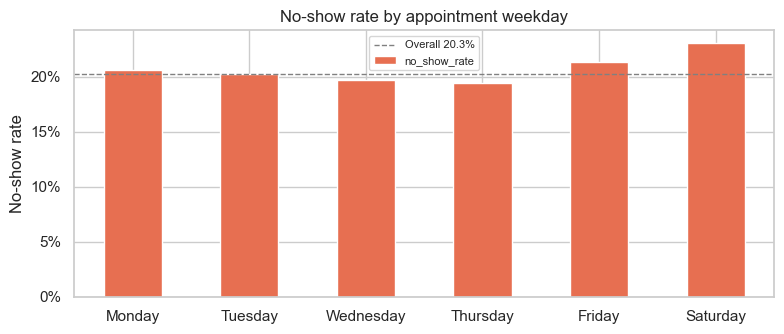

,appointments,no_show_rate,vs_baseline_pp
Weekday,,,
Monday,21902,0.206,0.350
Tuesday,24829,0.202,-0.034
Wednesday,25089,0.197,-0.543
Thursday,16658,0.195,-0.792
Friday,18465,0.213,1.077
Saturday,39,0.231,2.817


In [13]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
order = [d for d in order if d in df.Weekday.unique()]
plt.figure(figsize=(8, 3.5))
t = plot_rate("Weekday", order=order, title="No-show rate by appointment weekday")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
display(t.loc[order])

Weekday differences are **small** (within a point or two of baseline). Saturday has very few appointments, so its rate is noisy.

## 8. Neighbourhood

53 neighbourhoods with >= 500 appointments; no-show rate ranges 15.7% to 29.1%


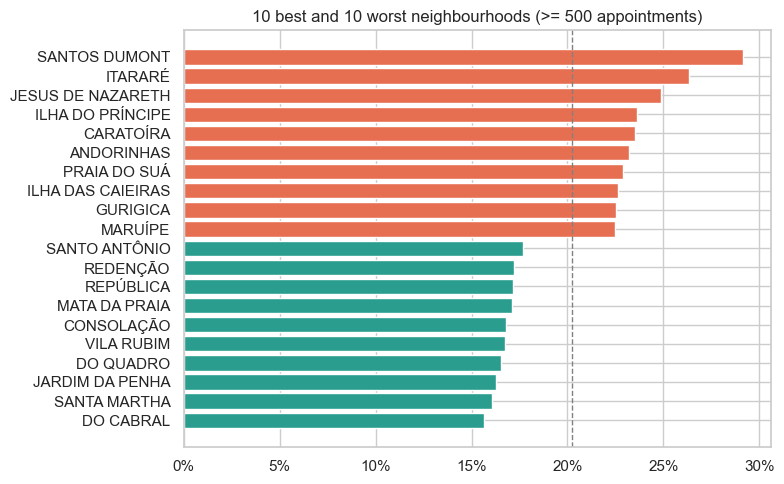

In [14]:
nb = rate_table("Neighbourhood")
nb = nb[nb.appointments >= 500].sort_values("no_show_rate")   # ignore tiny neighbourhoods
print(f"{len(nb)} neighbourhoods with >= 500 appointments; "
      f"no-show rate ranges {nb.no_show_rate.min():.1%} to {nb.no_show_rate.max():.1%}")

fig, ax = plt.subplots(figsize=(8, 5))
sel = pd.concat([nb.head(10), nb.tail(10)])
ax.barh(sel.index, sel.no_show_rate,
        color=["#2a9d8f"] * 10 + ["#e76f51"] * 10)
ax.axvline(BASE, ls="--", color="gray", lw=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("10 best and 10 worst neighbourhoods (>= 500 appointments)")
plt.tight_layout(); plt.show()

Neighbourhood shows a **moderate spread** of about 13 percentage points (about 16% to 29%) between the best and worst areas with a meaningful number of appointments. This probably reflects access, transport, and socioeconomic factors that the dataset doesn't capture directly.

## 9. Patient history: repeat no-shows

,appointments,no_show_rate,vs_baseline_pp
History,,,
Previously always showed,31146,0.171,-3.138
First visit,60270,0.195,-0.750
Has missed before,15566,0.294,9.182


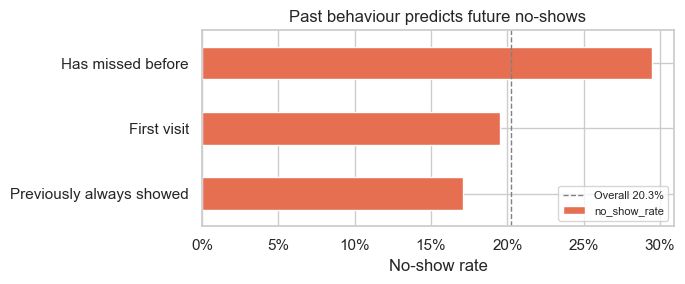

In [15]:
# For each appointment, count the patient's *previous* appointments and previous no-shows
d = df.sort_values(["PatientId", "AppointmentDay", "AppointmentID"]).copy()
g = d.groupby("PatientId")
d["PrevAppts"] = g.cumcount()
d["PrevNoShows"] = g.NoShow.cumsum() - d.NoShow

d["History"] = np.select(
    [d.PrevAppts == 0, d.PrevNoShows == 0, d.PrevNoShows >= 1],
    ["First visit", "Previously always showed", "Has missed before"], default="")

hist = rate_table("History", d).loc[["Previously always showed", "First visit", "Has missed before"]]
display(hist)

plt.figure(figsize=(7, 3))
plot_rate("History", data=d, horizontal=True,
          order=["Previously always showed", "First visit", "Has missed before"],
          title="Past behaviour predicts future no-shows")
plt.tight_layout(); plt.show()

df = df.join(d[["PrevAppts", "PrevNoShows"]])

**Past behaviour is a strong predictor.** Patients who have **missed an appointment before** are far more likely to miss again. Patients with a record of showing up are the most reliable group.
(The dataset covers only about 6 weeks of appointments, so "history" here is short, but the signal is still clear.)

## 10. Statistical significance summary

A chi-square test of independence for each categorical factor against the outcome, plus **Cramér's V** for effect size (0 = no association; ~0.1 is small).
With about 107k rows almost everything is "significant", so **effect size is the number that matters**. (SMS_received ranks high here only because of its confounding with lead time; see section 6.)

In [16]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    return chi2, p, np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

factors = ["LeadBand", "AgeGroup", "SMS_received", "Scholarship", "Hypertension",
           "Diabetes", "Alcoholism", "Handicap", "Gender", "Weekday", "Neighbourhood"]
res = []
for f in factors:
    chi2, p, v = cramers_v(df[f], df.NoShow)
    res.append({"factor": f, "chi2": chi2, "p_value": p, "cramers_v": v})
sig = pd.DataFrame(res).set_index("factor").sort_values("cramers_v", ascending=False)
display(sig.style.format({"chi2": "{:,.0f}", "p_value": "{:.2e}", "cramers_v": "{:.3f}"})
          .bar(subset="cramers_v", color="#e76f51"))

# Continuous variables: Mann-Whitney U
for col in ["Age", "LeadDays"]:
    a, b = df.loc[df.Showed_up, col], df.loc[~df.Showed_up, col]
    u, p = stats.mannwhitneyu(a, b)
    print(f"{col:9s} median showed={a.median():.0f}  no-show={b.median():.0f}  Mann-Whitney p={p:.1e}")

,chi2,p_value,cramers_v
factor,,,
LeadBand,"9,329",0.00e+00,0.295
SMS_received,"1,734",0.00e+00,0.127
AgeGroup,793,5.42e-166,0.086
Neighbourhood,509,1.14e-63,0.069
Hypertension,148,4.49e-34,0.037
Scholarship,92,7.63e-22,0.029
Diabetes,27,2.14e-07,0.016
Weekday,26,8.25e-05,0.016
Handicap,6,1.09e-02,0.008


Age       median showed=39  no-show=33  Mann-Whitney p=7.3e-111
LeadDays  median showed=2  no-show=11  Mann-Whitney p=0.0e+00


## 11. Predictive model

Can we predict no-shows from these features? We fit an interpretable **logistic regression** (odds ratios) and a **random forest** (non-linear benchmark).
`Neighbourhood` is left out to keep the model simple and interpretable.

Logistic regression  ROC AUC = 0.731
Random forest        ROC AUC = 0.742

Random forest classification report (threshold 0.5, balanced class weights):
              precision    recall  f1-score   support

   Showed up       0.91      0.56      0.70     21327
     No-show       0.32      0.79      0.45      5419

    accuracy                           0.61     26746
   macro avg       0.62      0.68      0.57     26746
weighted avg       0.79      0.61      0.65     26746



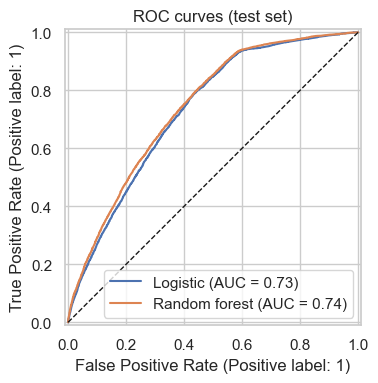

In [17]:
features = ["Age", "LeadDays", "SameDay", "Male", "Scholarship", "Hypertension", "Diabetes",
            "Alcoholism", "Handicap", "SMS_received", "PrevAppts", "PrevNoShows"]
X = (df.assign(SameDay=(df.LeadDays == 0), Male=(df.Gender == "M"))[features]).astype(float)
y = df.NoShow

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
logit.fit(X_tr, y_tr)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced",
                            n_jobs=-1, random_state=42)
rf.fit(X_tr, y_tr)

for name, m in [("Logistic regression", logit), ("Random forest", rf)]:
    print(f"{name:20s} ROC AUC = {roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]):.3f}")

print("\nRandom forest classification report (threshold 0.5, balanced class weights):")
print(classification_report(y_te, rf.predict(X_te), target_names=["Showed up", "No-show"]))

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_estimator(logit, X_te, y_te, ax=ax, name="Logistic")
RocCurveDisplay.from_estimator(rf, X_te, y_te, ax=ax, name="Random forest")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title("ROC curves (test set)")
plt.tight_layout(); plt.show()

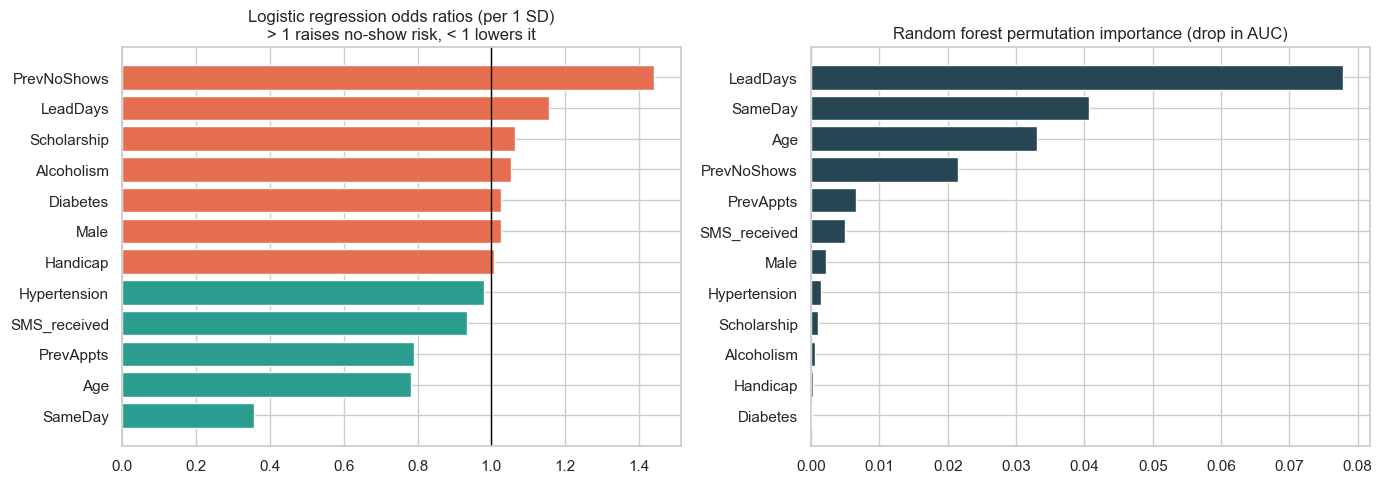

,odds_ratio,rf_importance
LeadDays,1.156,0.078
SameDay,0.357,0.041
Age,0.783,0.033
PrevNoShows,1.441,0.021
PrevAppts,0.791,0.007
SMS_received,0.934,0.005
Male,1.025,0.002
Hypertension,0.981,0.001
Scholarship,1.064,0.001
Alcoholism,1.053,0.001


In [18]:
# Logistic regression: odds ratio per 1 standard deviation (continuous) / for the flag (binary)
coefs = pd.Series(logit[-1].coef_[0], index=features)
odds = np.exp(coefs).sort_values()
colors = ["#2a9d8f" if v < 1 else "#e76f51" for v in odds]

# Random forest: permutation importance on the test set
pi = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(odds.index, odds.values, color=colors)
axes[0].axvline(1, color="black", lw=1)
axes[0].set_title("Logistic regression odds ratios (per 1 SD)\n> 1 raises no-show risk, < 1 lowers it")
axes[1].barh(imp.index, imp.values, color="#264653")
axes[1].set_title("Random forest permutation importance (drop in AUC)")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"odds_ratio": np.exp(coefs), "rf_importance": pd.Series(pi.importances_mean, index=features)})
          .sort_values("rf_importance", ascending=False))

**Model takeaways:**
- The model ranks no-show risk **moderately well** (AUC about 0.7–0.75). That's useful for prioritising reminders, but far from perfect. Much of why people miss appointments isn't in this data.
- **Lead time / same-day booking** and **prior no-shows** dominate. Age is next.
- Once lead time is controlled for, **SMS reminders reduce** the odds of a no-show (odds ratio < 1), which confirms the stratified analysis in section 6.
- Gender, alcoholism and handicap add almost nothing.

## 12. Key takeaways: showed up vs. no-show

| Factor | Patients who **showed up** tend to... | Patients who **didn't** tend to... | Strength |
|---|---|---|---|
| **Lead time** | book same-day or within a few days | have waited 1+ weeks (and longer waits are worse) | **Strongest** |
| **History** | have a record of attending | have missed an appointment before | **Strong** |
| **Age** | be older (median ~38); 55+ most reliable | be younger; teens and young adults (13–25) miss most | Moderate |
| **SMS reminder** | have received one (within the same lead time) | have *not* received one | Moderate (hidden by confounding) |
| **Welfare (Scholarship)** | not be enrolled | be enrolled in Bolsa Família (lower income) | Small |
| **Chronic conditions** | have hypertension or diabetes (raw) | not have them | None once age is controlled for |
| **Neighbourhood** | live in certain areas | live in other areas (about 13 pp spread) | Small–moderate |
| **Gender, weekday, alcoholism, handicap** | no meaningful difference | no meaningful difference | Negligible |

**Practical implications**
1. **Shorten the wait.** Every extra day between booking and appointment raises no-show risk. Same-day and next-few-day slots are the most reliable.
2. **Target reminders** at long-lead appointments, younger patients, and anyone with a prior no-show. The data suggests reminders help once confounding is removed.
3. **Use history.** A patient's past attendance is one of the cheapest and most predictive signals for overbooking or confirmation calls.

**Caveats:** this is observational data (correlation, not causation). The data covers a short window (~6 weeks) in one city, and important drivers like transport, appointment type, and weather aren't recorded.

---
# 13. Deep dive: routine vs. need-driven bookings for kids and seniors

**Questions**
1. For **kids and seniors who booked ahead**, did SMS reminders help?
2. Among kids and seniors who **missed before**, were their booked-ahead appointments missed again?
3. Does booking **within a week** (a sign of real need) mean people intend to keep the appointment?

**Working hypothesis (from the analyst):** routine, booked-ahead appointments are more fragile. Parents may only realize after a reminder that they can't make it, and seniors may forget or be unable to arrange transport. A booking made within a week reflects real need and therefore intent to attend.

**Proxy for appointment type.** The dataset has **no appointment-type field** (routine / follow-up / urgent), so we use lead time as a stand-in:

| Booking type | Lead time | Interpretation |
|---|---|---|
| Same day | 0 days | Walk-in or urgent; often booked during a visit |
| Within a week | 1–7 days | Need-driven: the patient wants to be seen soon |
| Routine | 8–30 days | Planned check-up or follow-up |
| Long-planned | 31+ days | Scheduled far ahead, e.g. periodic reviews |

**Note on SMS:** reminders were only sent for appointments booked **3+ days** ahead, so all SMS comparisons use lead times of 3 days or more.

In [19]:
import statsmodels.formula.api as smf

SEG_LABELS = ["Kids (0-12)", "Teens (13-17)", "Adults (18-59)", "Seniors (60+)"]
BOOK_LABELS = ["Same day", "Within a week", "Routine (8-30d)", "Long-planned (31d+)"]

d13 = d.copy()   # appointment-level frame with history columns from section 9
d13 = d13.rename(columns={"Hipertension": "Hypertension", "Date.diff": "LeadDays"})
d13["Segment"] = pd.cut(d13.Age, [-1, 12, 17, 59, 200], labels=SEG_LABELS)
d13["Booking"] = pd.cut(d13.LeadDays, [-1, 0, 7, 30, 200], labels=BOOK_LABELS)
d13["MissedBefore"] = (d13.PrevNoShows > 0).astype(int)

display(pd.crosstab(d13.Segment, d13.Booking, margins=True))

Booking,Same day,Within a week,Routine (8-30d),Long-planned (31d+),All
Segment,,,,,
Kids (0-12),7274,3923,4663,1636,17496
Teens (13-17),2530,1539,1742,532,6343
Adults (18-59),21029,18317,16980,5645,61971
Seniors (60+),6321,7667,5001,2183,21172
All,37154,31446,28386,9996,106982


## 13.1 Does booking within a week signal intent to keep the appointment?

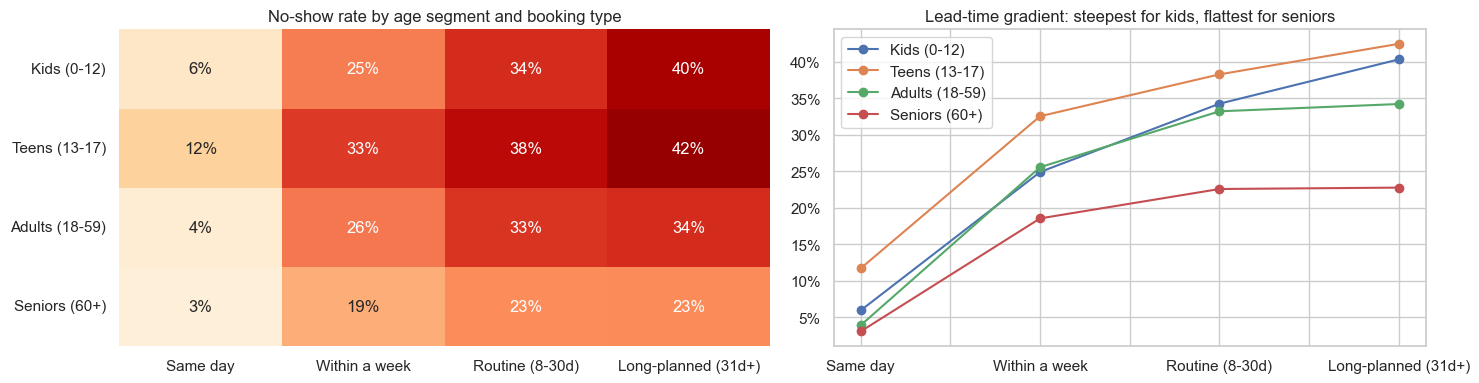

,% of appointments booked 8+ days ahead,% of no-shows booked 8+ days ahead
Segment,,
Kids (0-12),36%,62%
Teens (13-17),36%,53%
Adults (18-59),37%,58%
Seniors (60+),34%,50%


In [20]:
rate = d13.pivot_table(index="Segment", columns="Booking", values="NoShow", aggfunc="mean", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(rate, annot=True, fmt=".0%", cmap="OrRd", vmin=0, vmax=0.45, cbar=False, ax=axes[0])
axes[0].set_title("No-show rate by age segment and booking type"); axes[0].set_xlabel(""); axes[0].set_ylabel("")

rate.T.plot(marker="o", ax=axes[1])
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Lead-time gradient: steepest for kids, flattest for seniors")
axes[1].set_xlabel(""); axes[1].legend(title="")
plt.tight_layout(); plt.show()

# Where do the no-shows come from?
share = d13.groupby("Segment", observed=True)[["LeadDays", "NoShow"]].apply(lambda x: pd.Series({
    "% of appointments booked 8+ days ahead": x.LeadDays.ge(8).mean(),
    "% of no-shows booked 8+ days ahead": x.loc[x.NoShow == 1, "LeadDays"].ge(8).mean()}))
display(share.style.format("{:.0%}"))

**Reading this:**
- **The strongest intent signal is same-day booking**, not "within a week". Same-day no-show is 3–6% for kids, adults and seniors (12% for teens). Once there's even a 1–7 day gap, the rate jumps to about 19–26%.
- **Within a week is better than routine, but only partly.** Kids go from about 25% (within a week) to 34% (routine) to 40% (long-planned). For seniors the curve is flat: 19% → 23% → 23%.
- **Routine bookings are where kids' no-shows come from.** About 36% of kids' appointments are booked 8+ days ahead, but those produce about **62% of their no-shows**.
- **Seniors are the most reliable group at every lead time.** Booking ahead hurts them much less than it hurts kids.

## 13.2 For kids and seniors who booked ahead, did reminders help?

In [21]:
sms_base = d13[d13.LeadDays >= 3].copy()
sms_base["Booking3"] = pd.cut(sms_base.LeadDays, [2, 7, 30, 200],
                              labels=["Within a week (3-7d)", "Routine (8-30d)", "Long-planned (31d+)"])

def prop_diff_ci(g):
    a, b = g[g.SMS_received].NoShow, g[~g.SMS_received].NoShow
    p1, p0 = a.mean(), b.mean()
    se = np.sqrt(p1 * (1 - p1) / len(a) + p0 * (1 - p0) / len(b))
    diff = p1 - p0
    return pd.Series({"no_SMS": p0, "SMS": p1, "n_no_SMS": len(b), "n_SMS": len(a),
                      "diff_pp": diff * 100, "ci_low_pp": (diff - 1.96 * se) * 100,
                      "ci_high_pp": (diff + 1.96 * se) * 100})

sms_tbl = sms_base.groupby(["Segment", "Booking3"], observed=True).apply(prop_diff_ci, include_groups=False)
display(sms_tbl.style.format({"no_SMS": "{:.1%}", "SMS": "{:.1%}", "n_no_SMS": "{:,.0f}", "n_SMS": "{:,.0f}",
                              "diff_pp": "{:+.1f}", "ci_low_pp": "{:+.1f}", "ci_high_pp": "{:+.1f}"}))

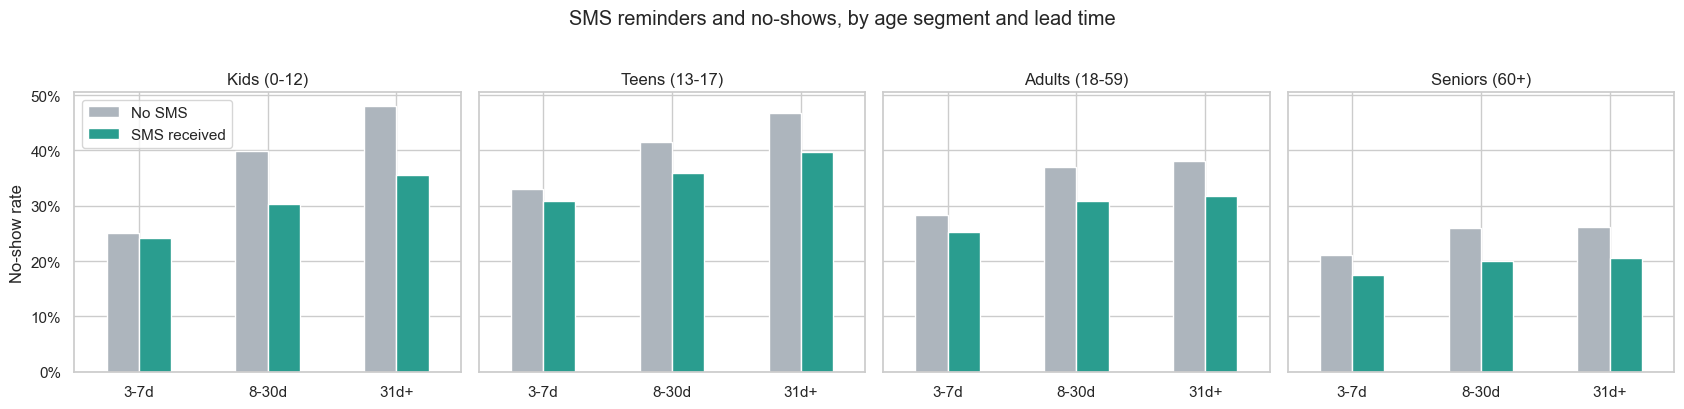

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, seg in zip(axes, SEG_LABELS):
    t = sms_tbl.loc[seg][["no_SMS", "SMS"]]
    t.columns = ["No SMS", "SMS received"]
    t.plot.bar(ax=ax, color=["#adb5bd", "#2a9d8f"], rot=0, legend=(seg == SEG_LABELS[0]))
    ax.set_title(seg); ax.set_xlabel("")
    ax.set_xticklabels(["3-7d", "8-30d", "31d+"])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("No-show rate")
fig.suptitle("SMS reminders and no-shows, by age segment and lead time", y=1.02)
plt.tight_layout(); plt.show()

These raw comparisons don't account for other differences between patients. Below, a **logistic regression** estimates the SMS effect for each age segment while holding constant lead time, prior no-shows, welfare enrolment and gender.
An **odds ratio below 1** means reminders reduce the odds of a no-show.

,SMS odds ratio,95% CI low,95% CI high,p_value
segment,,,,
Kids,0.73,0.66,0.80,3.6e-12
Teens,0.83,0.72,0.96,9.9e-03
Adults,0.80,0.76,0.84,1.1e-20
Seniors,0.74,0.68,0.81,5.3e-11


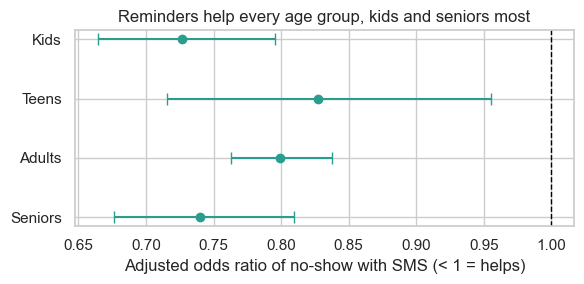

Share of 3+ day appointments that got an SMS, by appointment month:
AppointmentDay
June    0.820
May     0.520
April   0.790
Name: SMS_received, dtype: float64


In [23]:
model_df = sms_base.assign(Seg=sms_base.Segment.cat.rename_categories(["Kids", "Teens", "Adults", "Seniors"]),
                           SMS=sms_base.SMS_received.astype(int))
logit13 = smf.logit("NoShow ~ SMS * C(Seg, Treatment('Kids')) + np.log1p(LeadDays) + MissedBefore"
                    " + Scholarship + C(Gender)", data=model_df).fit(disp=0)

names = list(logit13.params.index)
rows = []
for seg in ["Kids", "Teens", "Adults", "Seniors"]:
    w = np.zeros(len(names)); w[names.index("SMS")] = 1
    if seg != "Kids":
        w[names.index(f"SMS:C(Seg, Treatment('Kids'))[T.{seg}]")] = 1
    t = logit13.t_test(w)
    lo, hi = np.exp(t.conf_int()[0])
    rows.append({"segment": seg, "SMS odds ratio": float(np.exp(t.effect[0])),
                 "95% CI low": lo, "95% CI high": hi, "p_value": float(t.pvalue)})
or_tbl = pd.DataFrame(rows).set_index("segment")
display(or_tbl.style.format({"SMS odds ratio": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}", "p_value": "{:.1e}"}))

fig, ax = plt.subplots(figsize=(6, 3))
y = np.arange(len(or_tbl))[::-1]
ax.errorbar(or_tbl["SMS odds ratio"], y,
            xerr=[or_tbl["SMS odds ratio"] - or_tbl["95% CI low"], or_tbl["95% CI high"] - or_tbl["SMS odds ratio"]],
            fmt="o", color="#2a9d8f", capsize=4)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_yticks(y); ax.set_yticklabels(or_tbl.index)
ax.set_xlabel("Adjusted odds ratio of no-show with SMS (< 1 = helps)")
ax.set_title("Reminders help every age group, kids and seniors most")
plt.tight_layout(); plt.show()

# Was SMS targeted at riskier patients? SMS coverage by month suggests an operational change instead
print("Share of 3+ day appointments that got an SMS, by appointment month:")
print(sms_base.groupby(sms_base.AppointmentDay.dt.month_name(), sort=False).SMS_received.mean().round(2))

**Reading this:**
- **Yes, reminders helped kids and seniors who booked ahead, and they're the two groups that benefit most.** After adjustment, an SMS cuts the odds of a no-show by about **27% for kids and 26% for seniors**, compared with about 20% for adults and 17% for teens.
- **The benefit grows with lead time.** For kids, the drop is about 10–12 points on routine and long-planned bookings (e.g. 48% → 36% at 31+ days), but **almost nothing** for within-a-week bookings (25% → 24%, not significant). Seniors get a steadier 3.5–6 point reduction at every lead time.
- **What this says about your hypothesis:**
  - *"Parents only realize after the reminder that they can't go."* If reminders mostly surfaced conflicts, kids with an SMS would miss *more* often. They miss less. So reminders mainly fix **forgetting**, not hidden conflicts. Note that **cancellations aren't recorded** in this dataset, so a reminder that led a parent to cancel early (freeing the slot) is invisible here.
  - For **within-a-week kids' bookings**, reminders don't help because the parent already knows about the appointment. That's consistent with "short lead time = intent".
  - For **seniors**, reminders help even on short bookings. That fits forgetting more than transport problems, since an SMS can't fix transport. Transport barriers would show up as the remaining 18–20% no-show rate that persists *despite* the reminder.
- SMS coverage dropped from about 80% to about 52% in May, which looks operational rather than risk-targeted. Combined with lead times being nearly identical with and without SMS inside each band, this makes the comparison reasonably fair. It is still observational, not a randomized trial.

## 13.3 Did kids and seniors who missed before miss their booked-ahead appointments again?

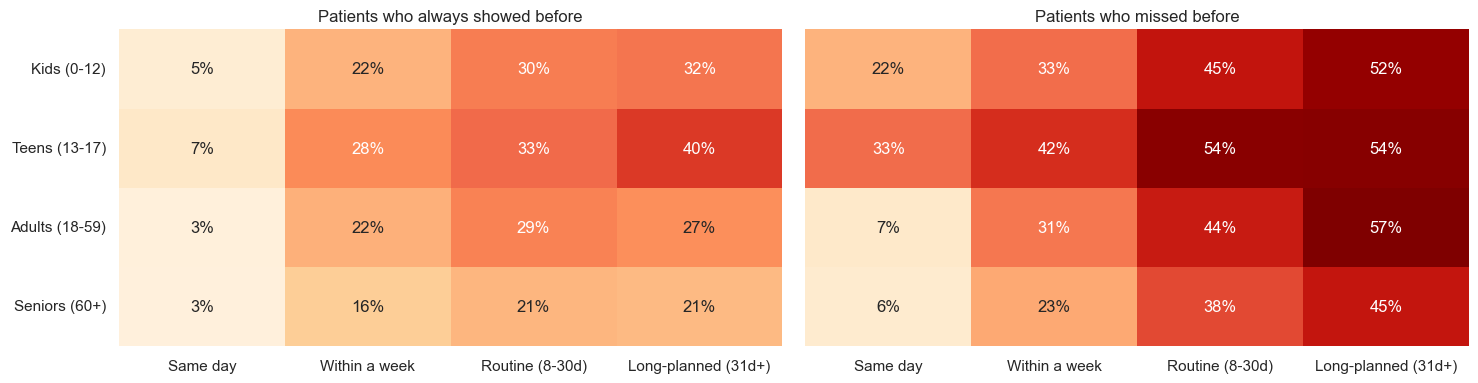

In [24]:
d13["History"] = np.select([d13.PrevAppts == 0, d13.MissedBefore == 1],
                           ["First visit", "Missed before"], default="Always showed before")
hist13 = d13[d13.History != "First visit"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, h in zip(axes, ["Always showed before", "Missed before"]):
    p = hist13[hist13.History == h].pivot_table(index="Segment", columns="Booking", values="NoShow",
                                                aggfunc="mean", observed=True)
    sns.heatmap(p, annot=True, fmt=".0%", cmap="OrRd", vmin=0, vmax=0.55, cbar=False, ax=ax)
    ax.set_title(f"Patients who {h.lower()}"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

display(hist13.pivot_table(index=["Segment", "History"], columns="Booking", values="NoShow",
                           aggfunc=["mean", "size"], observed=True)
              .style.format("{:.1%}", subset="mean").format("{:,.0f}", subset="size"))

,no_SMS,SMS,n_no_SMS,n_SMS,diff_pp,ci_low_pp,ci_high_pp
Segment,,,,,,,
Kids (0-12),56.5%,37.6%,336,380,-18.9,-26.1,-11.7
Teens (13-17),60.8%,47.9%,158,192,-12.8,-23.2,-2.5
Adults (18-59),58.0%,38.0%,"1,513","1,915",-20.0,-23.3,-16.7
Seniors (60+),47.8%,31.5%,383,406,-16.3,-23.0,-9.5


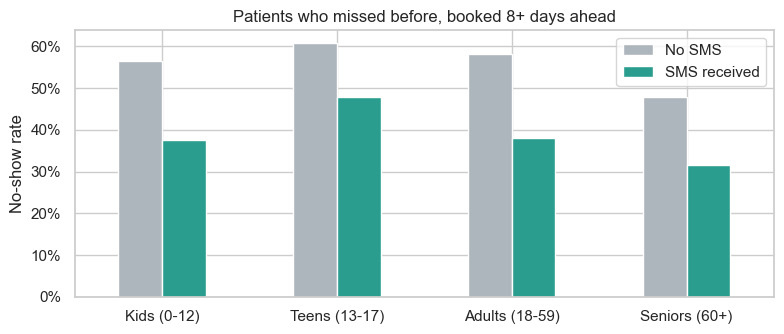

In [25]:
# Repeat missers on routine / long-planned bookings (8+ days): did a reminder help?
rep = d13[(d13.MissedBefore == 1) & (d13.LeadDays >= 8)]
rep_tbl = rep.groupby("Segment", observed=True).apply(prop_diff_ci, include_groups=False)
display(rep_tbl.style.format({"no_SMS": "{:.1%}", "SMS": "{:.1%}", "n_no_SMS": "{:,.0f}", "n_SMS": "{:,.0f}",
                              "diff_pp": "{:+.1f}", "ci_low_pp": "{:+.1f}", "ci_high_pp": "{:+.1f}"}))

ax = rep_tbl[["no_SMS", "SMS"]].rename(columns={"no_SMS": "No SMS", "SMS": "SMS received"}).plot.bar(
    figsize=(8, 3.5), color=["#adb5bd", "#2a9d8f"], rot=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Patients who missed before, booked 8+ days ahead"); ax.set_xlabel(""); ax.set_ylabel("No-show rate")
plt.tight_layout(); plt.show()

**Reading this:**
- **Yes, past missers miss their booked-ahead appointments again, and the gap widens with lead time.** Kids with a prior miss have about a **45% no-show rate on routine bookings**, vs. about 30% for kids who always showed. For seniors it's about **38% vs. 21%**.
- Even **same-day** appointments for kids with a prior miss have a ~22% no-show rate (vs. ~5% for kids who always showed). The family's track record matters even when they booked on the spot.
- **Reminders matter most for this group.** Among patients who missed before and booked 8+ days ahead, an SMS goes with a no-show rate about **19 points lower for kids (57% → 38%)** and **16 points lower for seniors (48% → 32%)**.

## 13.4 Summary for this deep dive

| Question | Answer |
|---|---|
| Does booking within a week signal intent? | **Partly.** Same-day booking is the strong intent signal (about 3–6% no-show). Within a week (about 19–25%) beats routine bookings for kids (34–40%), but for seniors the advantage is small. |
| Did reminders help kids and seniors who booked ahead? | **Yes, more than any other age group** (adjusted odds about 27% lower). For kids, the benefit is concentrated in **routine and long-planned bookings**; for short bookings it's close to zero. |
| Did prior missers miss booked-ahead appointments again? | **Yes.** About 45% (kids) and 38% (seniors) on 8–30 day bookings, but a reminder cuts that by 16–19 points. |
| Reminder surfaces "can't go" vs. "forgot"? | The data points to **forgetting**: reminders lower no-shows rather than raise them. Cancellations aren't recorded, so the "realized they can't go" path can't be measured directly. |

**Operational implications**
1. **Kids' routine and long-planned visits** are the highest-yield reminder target, especially for families with a prior miss. Consider a **second reminder** or a confirm/reschedule prompt.
2. **Seniors:** keep reminding at every lead time. For the remaining ~20% who miss despite reminders, test **transport or caregiver outreach**, which the data can't measure but which fits what's left over.
3. **Within-a-week kids' bookings** don't benefit from SMS. Reminder budget is better spent elsewhere.
4. **Add an appointment-type field** (routine / follow-up / urgent) and **record cancellations**. Both would turn this proxy analysis into a direct one.

---
# 14. Full logistic regression: what independently predicts a no-show?

Section 11 used scikit-learn for prediction. Here we fit an **inferential** logistic regression with `statsmodels` on all ~107k appointments:
- **Outcome:** `NoShow` (1 = missed). An **odds ratio (OR) > 1 raises** the odds of missing; **< 1 lowers** them.
- **Each OR is adjusted** for every other variable in the model.
- **Standard errors are clustered by patient**, because many patients have several appointments.
- **Reference levels:** same-day booking, first visit, age 36–45, female, Wednesday.

In [26]:
m14 = d13.copy()
m14["AgeBand"] = pd.cut(m14.Age, [-1, 12, 17, 25, 35, 45, 55, 65, 200],
                        labels=["0-12", "13-17", "18-25", "26-35", "36-45", "46-55", "56-65", "66+"])
m14["Lead"] = pd.cut(m14.LeadDays, [-1, 0, 2, 7, 14, 30, 60, 200],
                     labels=["Same day", "1-2d", "3-7d", "8-14d", "15-30d", "31-60d", "60d+"])
m14["Hist"] = np.select([m14.PrevAppts == 0, m14.MissedBefore == 1],
                        ["First visit", "Missed before"], default="Always showed")
for c in ["SMS_received", "Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap"]:
    m14[c] = m14[c].astype(int)
m14["pid"] = pd.factorize(m14.PatientId)[0]

formula = ("NoShow ~ C(Lead, Treatment('Same day')) + SMS_received + C(Hist, Treatment('First visit'))"
           " + C(AgeBand, Treatment('36-45')) + Scholarship + Hypertension + Diabetes + Alcoholism + Handicap"
           " + C(Gender) + C(Weekday, Treatment('Wednesday'))")
full = smf.logit(formula, data=m14).fit(disp=0, cov_type="cluster", cov_kwds={"groups": m14.pid})

print(f"n = {int(full.nobs):,}   pseudo R² = {full.prsquared:.3f}   "
      f"AUC = {roc_auc_score(m14.NoShow, full.predict(m14)):.3f}")
full.summary2().tables[1].iloc[:, :4]

n = 106,982   pseudo R² = 0.123   AUC = 0.734


,Coef.,Std.Err.,z,P>|z|
Intercept,-3.205,0.045,-70.520,0.000
"C(Lead, Treatment('Same day'))[T.1-2d]",1.926,0.045,42.436,0.000
"C(Lead, Treatment('Same day'))[T.3-7d]",2.115,0.042,50.057,0.000
"C(Lead, Treatment('Same day'))[T.8-14d]",2.359,0.045,52.481,0.000
"C(Lead, Treatment('Same day'))[T.15-30d]",2.505,0.043,58.791,0.000
"C(Lead, Treatment('Same day'))[T.31-60d]",2.593,0.046,56.240,0.000
"C(Lead, Treatment('Same day'))[T.60d+]",2.518,0.064,39.117,0.000
"C(Hist, Treatment('First visit'))[T.Always showed]",-0.134,0.020,-6.765,0.000
"C(Hist, Treatment('First visit'))[T.Missed before]",0.588,0.029,20.469,0.000
"C(AgeBand, Treatment('36-45'))[T.0-12]",0.126,0.034,3.699,0.000


,odds_ratio,ci_low,ci_high,p_value
Lead time: 1-2d,6.86,6.28,7.50,0.0e+00
Lead time: 3-7d,8.29,7.63,9.01,0.0e+00
Lead time: 8-14d,10.58,9.69,11.55,0.0e+00
Lead time: 15-30d,12.25,11.27,13.31,0.0e+00
Lead time: 31-60d,13.36,12.21,14.63,0.0e+00
Lead time: 60d+,12.40,10.93,14.07,0.0e+00
History: Always showed,0.87,0.84,0.91,1.3e-11
History: Missed before,1.80,1.70,1.90,4.1e-93
Age: 0-12,1.13,1.06,1.21,2.2e-04
Age: 13-17,1.55,1.41,1.69,3.8e-21


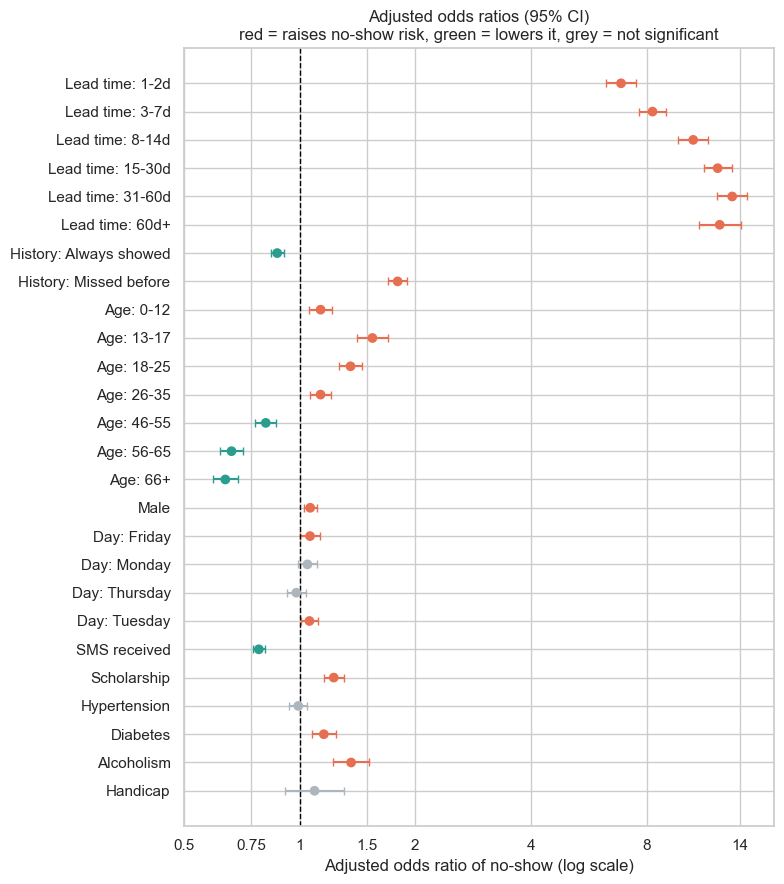

In [27]:
def clean(name):
    for pat, rep in [("C(Lead, Treatment('Same day'))[T.", "Lead time: "),
                     ("C(Hist, Treatment('First visit'))[T.", "History: "),
                     ("C(AgeBand, Treatment('36-45'))[T.", "Age: "),
                     ("C(Weekday, Treatment('Wednesday'))[T.", "Day: "),
                     ("C(Gender)[T.M", "Male"), ("_received", " received")]:
        name = name.replace(pat, rep)
    return name.rstrip("]")

ci = full.conf_int()
or_full = pd.DataFrame({"odds_ratio": np.exp(full.params), "ci_low": np.exp(ci[0]),
                        "ci_high": np.exp(ci[1]), "p_value": full.pvalues}).drop("Intercept")
or_full.index = [clean(i) for i in or_full.index]
display(or_full.style.format({"odds_ratio": "{:.2f}", "ci_low": "{:.2f}", "ci_high": "{:.2f}", "p_value": "{:.1e}"})
               .background_gradient(subset="odds_ratio", cmap="RdYlGn_r", vmin=0.5, vmax=1.5))

plot_df = or_full.drop(index=[i for i in or_full.index if i == "Day: Saturday"])  # 39 appts, CI too wide to show
fig, ax = plt.subplots(figsize=(8, 9))
y = np.arange(len(plot_df))[::-1]
colors = np.where(plot_df.ci_high < 1, "#2a9d8f", np.where(plot_df.ci_low > 1, "#e76f51", "#adb5bd"))
for yi, (_, r), c in zip(y, plot_df.iterrows(), colors):
    ax.errorbar(r.odds_ratio, yi, xerr=[[r.odds_ratio - r.ci_low], [r.ci_high - r.odds_ratio]],
                fmt="none", ecolor=c, capsize=3)
ax.scatter(plot_df.odds_ratio, y, c=colors, zorder=3)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_xscale("log"); ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 4, 8, 14]); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "4", "8", "14"])
ax.set_yticks(y); ax.set_yticklabels(plot_df.index)
ax.set_xlabel("Adjusted odds ratio of no-show (log scale)")
ax.set_title("Adjusted odds ratios (95% CI)\nred = raises no-show risk, green = lowers it, grey = not significant")
plt.tight_layout(); plt.show()

Odds ratios can be hard to interpret, so the next cell converts them to **predicted no-show rates**. For each level of a factor, we set every appointment to that level, keep everything else as observed, and average the model's predictions.

In [28]:
def predicted_rates(col, levels):
    out = {}
    for lv in levels:
        tmp = m14.copy(); tmp[col] = lv
        if col == "Lead":
            tmp["SMS_received"] = 0   # isolate lead time from reminders
        out[lv] = full.predict(tmp).mean()
    return pd.Series(out, name="predicted no-show rate")

for col, levels in [("Lead", ["Same day", "1-2d", "3-7d", "8-14d", "15-30d", "31-60d"]),
                    ("Hist", ["Always showed", "First visit", "Missed before"]),
                    ("AgeBand", ["0-12", "13-17", "18-25", "36-45", "56-65", "66+"]),
                    ("SMS_received", [0, 1]), ("Scholarship", [0, 1])]:
    display(predicted_rates(col, levels).to_frame().T.style.format("{:.1%}").set_caption(col))

,Same day,1-2d,3-7d,8-14d,15-30d,31-60d
predicted no-show rate,4.6%,24.2%,27.7%,32.6%,35.8%,37.8%


,Always showed,First visit,Missed before
predicted no-show rate,17.6%,19.4%,28.8%


,0-12,13-17,18-25,36-45,56-65,66+
predicted no-show rate,22.7%,27.8%,25.5%,20.7%,15.3%,14.9%


,0,1
predicted no-show rate,21.9%,18.4%


,0,1
predicted no-show rate,19.9%,23.0%


**What the full model says:**

| Factor | Adjusted effect | Takeaway |
|---|---|---|
| **Lead time** | OR about **7 (1–2 days) up to 13 (31–60 days)** vs. same day | By far the biggest factor. Even a 1–2 day gap multiplies the odds of missing about 7x compared with booking the same day. |
| **Missed before** | OR **1.80** vs. first visit; "always showed" 0.87 | A prior no-show nearly doubles the odds, even with lead time and age held constant. |
| **SMS reminder** | OR **0.78** | A reminder cuts the odds of missing by about 22%. This confirms the raw "SMS → more no-shows" pattern was confounding. |
| **Age** | Ages 13–17: **1.55**; 18–25: 1.36; 56–65: 0.67; 66+: **0.64** (vs. 36–45) | Teens and young adults are the riskiest; patients over 55 are the most reliable. |
| **Welfare (Scholarship)** | OR **1.23** | A real but modest effect, likely a proxy for low income or access barriers. |
| **Alcoholism** | OR **1.36** | **Hidden in the raw data** (20% vs. 20%). It shows up once age is controlled for, because people with alcoholism tend to be middle-aged, a lower-risk age group. |
| **Diabetes** | OR **1.16** | **Flips direction.** Raw, people with diabetes look more reliable (18% vs. 20%), but that's because they're older. At the same age, they're slightly *more* likely to miss. |
| **Hypertension** | OR 0.99 (not significant) | No independent effect. The raw "reliability" was entirely age. |
| **Gender** | Male OR 1.07 | Statistically detectable but tiny. |
| **Handicap, weekday** | About 1.0 (Fri/Tue about 1.06) | Negligible. |

**Model fit:** AUC about 0.73 and pseudo R² about 0.12. These factors clearly matter, but they explain only part of why people miss appointments. Unrecorded factors (transport, appointment type, work schedules, weather) carry a lot of weight.

---
# 15. Segmentation: clustering vs. PCA vs. supervised models, and the recommended approach

The full logistic model has a low pseudo R² (about 0.12). Would an **unsupervised** approach (k-means clustering, or PCA) give a better handle on who shows up?
We compare all approaches on the **same held-out test set** using ROC AUC, then turn the best interpretable option into usable segments.

> **Decision recorded:** the **3-level decision tree** (section 15.3) is the recommended segmentation approach. It is nearly as accurate as the best model, far better than clustering or PCA, and every segment is a plain-English rule staff can apply.

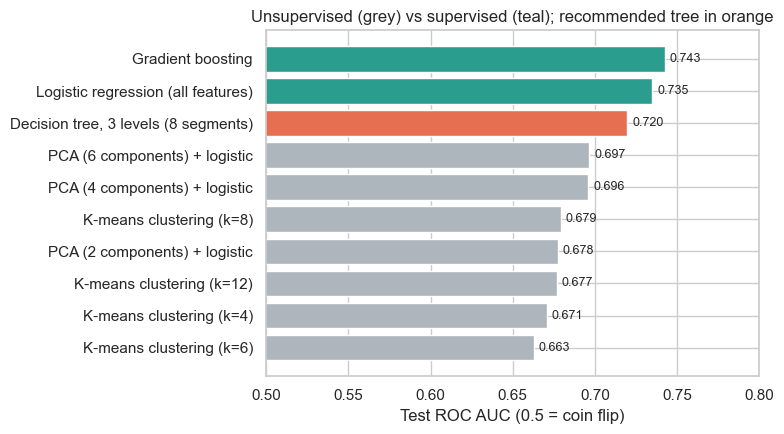

,test ROC AUC
K-means clustering (k=6),0.663
K-means clustering (k=4),0.671
K-means clustering (k=12),0.677
PCA (2 components) + logistic,0.678
K-means clustering (k=8),0.679
PCA (4 components) + logistic,0.696
PCA (6 components) + logistic,0.697
"Decision tree, 3 levels (8 segments)",0.720
Logistic regression (all features),0.735
Gradient boosting,0.743


In [29]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import HistGradientBoostingClassifier

seg_df = df.assign(SameDay=(df.LeadDays == 0).astype(int), Male=(df.Gender == "M").astype(int))
F15 = ["Age", "LeadDays", "SameDay", "SMS_received", "Scholarship", "Hypertension", "Diabetes",
       "Alcoholism", "Handicap", "Male", "PrevAppts", "PrevNoShows"]
X15 = seg_df[F15].astype(float)
y15 = seg_df.NoShow
Xtr, Xte, ytr, yte = train_test_split(X15, y15, test_size=0.25, stratify=y15, random_state=0)

# Scaled copy with log lead time, for the distance-based methods (k-means, PCA, logistic)
def prep(X):
    return X.assign(LeadDays=np.log1p(X.LeadDays))
scaler = StandardScaler().fit(prep(Xtr))
Ztr, Zte = scaler.transform(prep(Xtr)), scaler.transform(prep(Xte))

results = {}

# 1. K-means: clusters ignore the outcome; score each test row with its cluster's training no-show rate
for k in [4, 6, 8, 12]:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Ztr)
    cl_rate = pd.Series(ytr.values).groupby(km.labels_).mean()
    results[f"K-means clustering (k={k})"] = roc_auc_score(yte, cl_rate.reindex(km.predict(Zte)).values)

# 2. PCA: keep the top components, then fit a logistic regression on them
pca_full = PCA().fit(Ztr)
for n in [2, 4, 6]:
    pipe = make_pipeline(PCA(n_components=n), LogisticRegression(max_iter=1000)).fit(Ztr, ytr)
    results[f"PCA ({n} components) + logistic"] = roc_auc_score(yte, pipe.predict_proba(Zte)[:, 1])

# 3. Supervised models
lr15 = LogisticRegression(max_iter=1000).fit(Ztr, ytr)
results["Logistic regression (all features)"] = roc_auc_score(yte, lr15.predict_proba(Zte)[:, 1])
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=0).fit(Xtr, ytr)
results["Decision tree, 3 levels (8 segments)"] = roc_auc_score(yte, tree.predict_proba(Xte)[:, 1])
hgb = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr)
results["Gradient boosting"] = roc_auc_score(yte, hgb.predict_proba(Xte)[:, 1])

res15 = pd.Series(results, name="test ROC AUC").sort_values()
kind = ["Unsupervised" if ("K-means" in i or "PCA" in i) else "Supervised" for i in res15.index]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(res15.index, res15.values, color=["#adb5bd" if k == "Unsupervised" else "#2a9d8f" for k in kind])
ax.barh(["Decision tree, 3 levels (8 segments)"], [results["Decision tree, 3 levels (8 segments)"]], color="#e76f51")
for i, v in enumerate(res15.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.5, 0.8); ax.set_xlabel("Test ROC AUC (0.5 = coin flip)")
ax.set_title("Unsupervised (grey) vs supervised (teal); recommended tree in orange")
plt.tight_layout(); plt.show()
res15.to_frame()

## 15.1 Why clustering and PCA underperform

Both methods are **unsupervised**: they never see whether a patient showed up. They organize the data around whatever varies most, which here is not what drives attendance.

,appointments,no_show_rate,median_age,median_lead_days,pct_SMS,pct_hypertension,pct_diabetes
cluster,,,,,,,
1,"19,833",4.7%,29,0,0%,4%,1%
2,"13,576",17.9%,62,4,34%,95%,38%
3,"1,661",18.3%,53,2,24%,44%,18%
4,"2,452",20.6%,50,1,25%,39%,10%
5,"7,304",23.9%,30,4,33%,13%,1%
0,"35,410",29.2%,32,11,51%,0%,0%


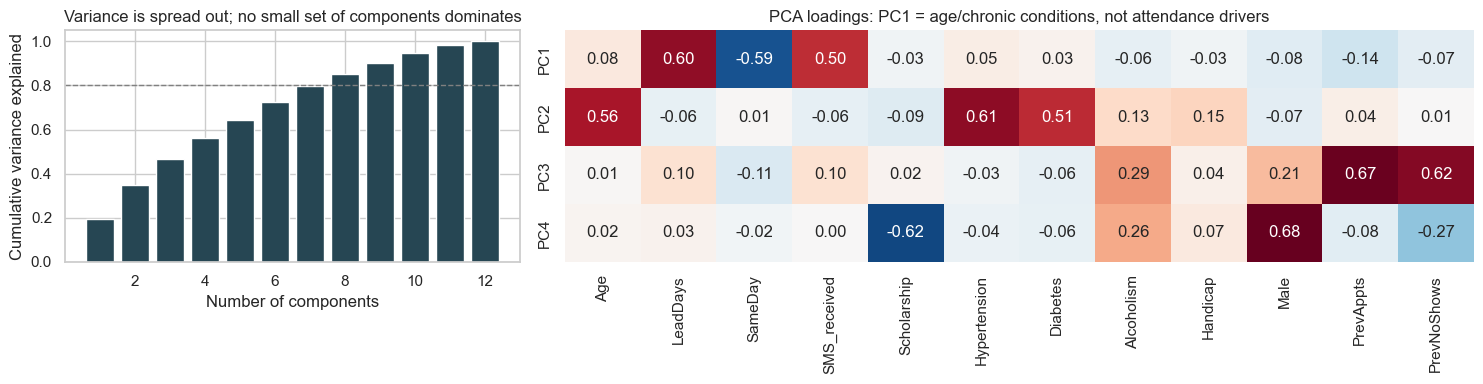

In [30]:
# What k-means actually found (k=6)
km6 = KMeans(n_clusters=6, n_init=10, random_state=0).fit(Ztr)
prof = (Xtr.assign(cluster=km6.labels_, NoShow=ytr.values)
           .groupby("cluster")
           .agg(appointments=("NoShow", "size"), no_show_rate=("NoShow", "mean"), median_age=("Age", "median"),
                median_lead_days=("LeadDays", "median"), pct_SMS=("SMS_received", "mean"),
                pct_hypertension=("Hypertension", "mean"), pct_diabetes=("Diabetes", "mean"))
           .sort_values("no_show_rate"))
display(prof.style.format({"no_show_rate": "{:.1%}", "pct_SMS": "{:.0%}", "pct_hypertension": "{:.0%}",
                           "pct_diabetes": "{:.0%}", "appointments": "{:,.0f}", "median_age": "{:.0f}",
                           "median_lead_days": "{:.0f}"}))

# What PCA's components are made of
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(range(1, len(F15) + 1), pca_full.explained_variance_ratio_.cumsum(), color="#264653")
axes[0].axhline(0.8, ls="--", color="gray", lw=1)
axes[0].set_xlabel("Number of components"); axes[0].set_ylabel("Cumulative variance explained")
axes[0].set_title("Variance is spread out; no small set of components dominates")
load = pd.DataFrame(pca_full.components_[:4].T, index=F15, columns=[f"PC{i}" for i in range(1, 5)])
sns.heatmap(load.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False, ax=axes[1])
axes[1].set_title("PCA loadings: PC1 = age/chronic conditions, not attendance drivers")
plt.tight_layout(); plt.show()

**Reading this:**
- **K-means** puts same-day bookings in one group and hypertension/diabetes patients in their own groups. But hypertension has **no independent effect** on attendance (section 14). The highest-risk cluster is basically "everyone under ~50 who booked ahead", which is too broad to act on.
- **PCA**'s first component is mostly **age plus chronic conditions**, because those variables move together. Lead time and prior no-shows, the strongest predictors, are spread across later components. With only 12 mostly yes/no features and little redundancy among them, PCA has nothing useful to compress, and it costs interpretability.
- **The ceiling is the data, not the method.** Gradient boosting, which can learn any interaction, beats plain logistic regression by only about 0.01 AUC. Every method stops around 0.75, because key drivers (appointment type, transport, work schedules, cancellations) aren't recorded.

## 15.2 Risk tiers from the logistic model

,appointments,actual_no_show,predicted,share_of_all_no_shows
tier,,,,
D1,2675,2.7%,2.7%,1%
D2,2675,3.7%,4.0%,2%
D3,2674,4.5%,5.1%,2%
D4,2675,13.5%,12.0%,7%
D5,2674,20.0%,20.0%,10%
D6,2675,25.2%,23.6%,12%
D7,2674,25.9%,26.7%,13%
D8,2675,29.6%,30.0%,15%
D9,2674,33.1%,34.2%,16%


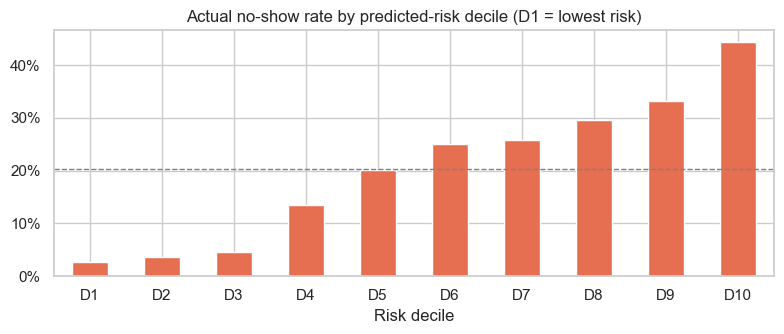

In [31]:
p_lr = lr15.predict_proba(Zte)[:, 1]
tiers = pd.qcut(pd.Series(p_lr).rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
tier_tbl = (pd.DataFrame({"tier": tiers, "NoShow": yte.values, "pred": p_lr})
              .groupby("tier", observed=True)
              .agg(appointments=("NoShow", "size"), actual_no_show=("NoShow", "mean"), predicted=("pred", "mean")))
tier_tbl["share_of_all_no_shows"] = (tier_tbl.actual_no_show * tier_tbl.appointments) / yte.sum()
display(tier_tbl.style.format({"actual_no_show": "{:.1%}", "predicted": "{:.1%}", "share_of_all_no_shows": "{:.0%}"}))

ax = tier_tbl.actual_no_show.plot.bar(figsize=(8, 3.5), color="#e76f51", rot=0)
ax.axhline(BASE, ls="--", color="gray", lw=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Actual no-show rate by predicted-risk decile (D1 = lowest risk)")
ax.set_xlabel("Risk decile"); plt.tight_layout(); plt.show()

## 15.3 Recommended: 3-level decision tree segments

A depth-3 tree (each segment has at least 500 training appointments) splits patients into **8 segments**, each defined by a plain-English rule.
No-show rates below are measured on the **held-out test set**.

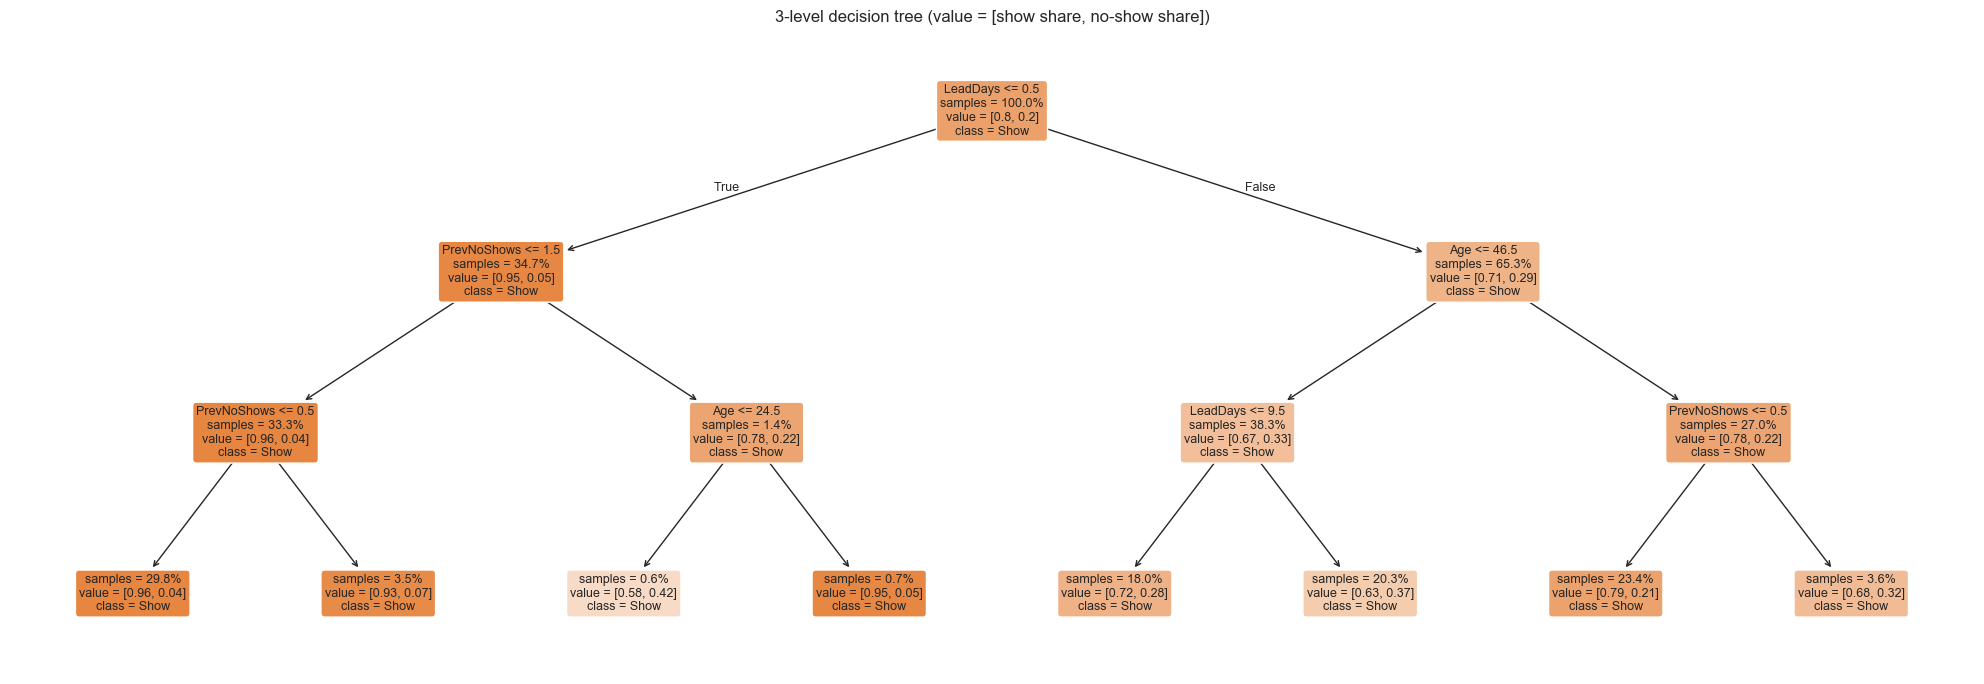

In [32]:
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(tree, feature_names=F15, class_names=["Show", "No-show"], filled=True, rounded=True,
          proportion=True, impurity=False, precision=2, fontsize=9, ax=ax)
ax.set_title("3-level decision tree (value = [show share, no-show share])")
plt.tight_layout(); plt.show()

,segment rule,tier,test_no_show_rate,share_of_appointments,share_of_no_shows,test_appointments
S1,"same-day booking, no prior no-shows",Low,3.5%,30%,5%,"8,027"
S2,"same-day booking, 2+ prior no-shows, age 25+",Low,6.8%,1%,0%,206
S3,"same-day booking, exactly 1 prior no-show",Low,7.8%,3%,1%,918
S4,"booked 1+ days ahead, age 47+, no prior no-shows",Medium,21.3%,23%,24%,"6,169"
S5,"booked 1-9 days ahead, age 46 or under",High,28.7%,18%,26%,"4,909"
S6,"booked 1+ days ahead, age 47+, 1+ prior no-shows",High,31.6%,4%,6%,976
S7,"booked 10+ days ahead, age 46 or under",High,36.2%,20%,36%,"5,365"
S8,"same-day booking, 2+ prior no-shows, age 24 or under",High,42.6%,1%,1%,176


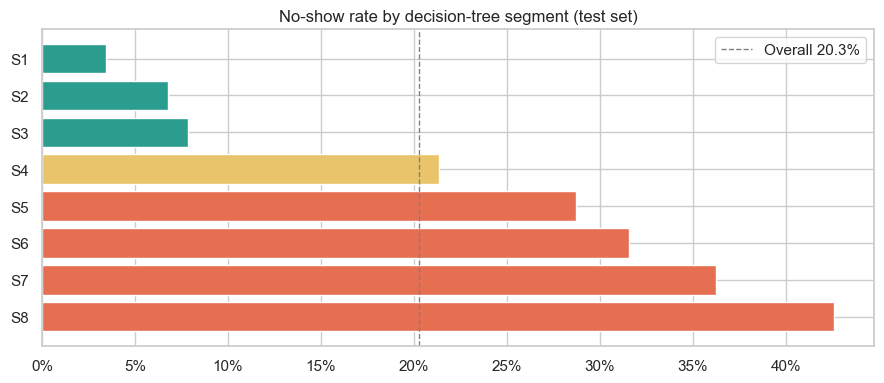

In [33]:
def leaf_rules(model, names):
    t = model.tree_
    rules = {}
    def walk(node, conds):
        if t.children_left[node] == -1:
            rules[node] = conds
            return
        f, thr = names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [(f, "<=", thr)])
        walk(t.children_right[node], conds + [(f, ">", thr)])
    walk(0, [])
    return rules

def describe(conds):
    # Merge all splits on the same feature into one range, then phrase it in plain English
    lo, hi = {}, {}
    for f, op, thr in conds:
        if op == ">":
            lo[f] = max(lo.get(f, -np.inf), np.floor(thr) + 1)   # integer-valued features
        else:
            hi[f] = min(hi.get(f, np.inf), np.floor(thr))
    parts = []
    for f in dict.fromkeys(c[0] for c in conds):
        l, h = lo.get(f, 0), hi.get(f, np.inf)
        if f in ("LeadDays", "SameDay"):
            if f == "SameDay":
                l, h = (1, np.inf) if h == 0 else (0, 0)
            txt = ("same-day booking" if h == 0 else f"booked {l:.0f}+ days ahead" if h == np.inf
                   else f"booked {l:.0f}-{h:.0f} days ahead")
        elif f == "Age":
            txt = (f"age {l:.0f}+" if h == np.inf else f"age {h:.0f} or under" if l == 0 else f"age {l:.0f}-{h:.0f}")
        elif f == "PrevNoShows":
            txt = ("no prior no-shows" if h == 0 else f"{l:.0f}+ prior no-shows" if h == np.inf
                   else f"exactly {l:.0f} prior no-show" if l == h else f"{l:.0f}-{h:.0f} prior no-shows")
        else:
            txt = f if l >= 1 else f"no {f}"
        parts.append(txt)
    return ", ".join(parts)

rules = leaf_rules(tree, F15)
leaf_te = tree.apply(Xte)
seg_tbl = (pd.DataFrame({"leaf": leaf_te, "NoShow": yte.values})
             .groupby("leaf").agg(test_appointments=("NoShow", "size"), test_no_show_rate=("NoShow", "mean")))
seg_tbl["share_of_appointments"] = seg_tbl.test_appointments / len(yte)
seg_tbl["share_of_no_shows"] = seg_tbl.test_no_show_rate * seg_tbl.test_appointments / yte.sum()
seg_tbl["segment rule"] = [describe(rules[l]) for l in seg_tbl.index]
seg_tbl = seg_tbl.sort_values("test_no_show_rate").reset_index(drop=True)
seg_tbl.index = [f"S{i}" for i in range(1, len(seg_tbl) + 1)]
seg_tbl["tier"] = pd.cut(seg_tbl.test_no_show_rate, [0, 0.10, 0.25, 1], labels=["Low", "Medium", "High"])
display(seg_tbl[["segment rule", "tier", "test_no_show_rate", "share_of_appointments", "share_of_no_shows", "test_appointments"]]
        .style.format({"test_no_show_rate": "{:.1%}", "share_of_appointments": "{:.0%}",
                       "share_of_no_shows": "{:.0%}", "test_appointments": "{:,.0f}"}))

colors = seg_tbl.tier.map({"Low": "#2a9d8f", "Medium": "#e9c46a", "High": "#e76f51"})
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(seg_tbl.index[::-1], seg_tbl.test_no_show_rate[::-1], color=colors[::-1])
ax.axvline(BASE, ls="--", color="gray", lw=1, label=f"Overall {BASE:.1%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("No-show rate by decision-tree segment (test set)"); ax.legend()
plt.tight_layout(); plt.show()

## 15.4 Conclusion and recorded decision

| Approach | Test AUC | Interpretable? | Verdict |
|---|---|---|---|
| K-means clustering | ~0.67–0.68 | Partly (clusters need interpreting) | Not recommended: ignores the outcome, groups by hypertension and age |
| PCA + logistic | below full logistic | No (components mix variables) | Not recommended: nothing redundant to compress, loses meaning |
| Logistic regression | ~0.74 | Yes (odds ratios) | Use for **explanation** (section 14) and **risk scores and deciles** (15.2) |
| Gradient boosting | ~0.75 | No | Barely better than logistic; not worth the opacity |
| **3-level decision tree** | **~0.72–0.73** | **Yes, plain-English rules** | **✅ Recommended for segmentation and operations** |

**Decision:** use the **3-level decision tree segments** as the working segmentation for no-show interventions:
| Tier | Segments (from 15.3) | Test no-show rate | Share of no-shows | Action |
|---|---|---|---|---|
| **Low** | Same-day bookings (except young repeat missers) | about 3–8% | about 6% | No reminder needed |
| **Medium** | Booked ahead, age 47+, no prior no-shows | about 21% | about 24% | Standard SMS reminder |
| **High** | Booked ahead and age 46 or under (1–9 days: about 29%; 10+ days: about 36%); booked ahead, age 47+, with a prior no-show (about 32%); same-day, age 24 or under, 2+ prior no-shows (about 43%, small) | about 29–43% | about **69%** | Second reminder, confirm/reschedule prompt or call; overbooking candidates |

The three high-risk segments hold about 43% of appointments but about **69% of all no-shows**. That's where intervention effort should go.

Use the logistic model's risk deciles when finer ranking is needed. **Revisit** the tree once appointment type and cancellations are recorded; those are the most likely ways past the ~0.75 AUC ceiling.

---
# 16. Final recommendation: use the 3-level decision tree to target no-show interventions

**Recommendation:** classify every booked appointment into a **Low / Medium / High** no-show risk tier using the 3-level decision tree from section 15.3, and match the intervention to the tier.

**Why this approach**
- **Accurate enough:** test AUC about 0.72, close to the best model (gradient boosting, about 0.74) and well above clustering (about 0.67) and PCA (about 0.69). See section 15.
- **Transparent:** it uses only three things known at booking time (**lead time, age, prior no-shows**), and every tier is a rule staff can apply without a model.
- **Consistent with the rest of the analysis:** these are the same three factors that dominate the logistic regression (section 14). Reminders are most effective exactly where the tree puts its high-risk tier: booked-ahead, younger patients and repeat missers (section 13).

## 16.1 The tier rules

| Tier | Rule (at time of booking) | No-show rate | Share of appointments | Share of no-shows |
|---|---|---|---|---|
| 🟢 **Low** | **Same-day** booking, unless the patient is **24 or under with 2+ prior no-shows** | about 3–8% | about 34% | about 7% |
| 🟡 **Medium** | Booked **1+ days ahead**, age **47+**, **no** prior no-shows | about 21% | about 23% | about 24% |
| 🔴 **High** | Booked **1+ days ahead** and age **46 or under** (any history) | about 29% (1–9 days) to 36% (10+ days) | about 38% | about 62% |
| 🔴 **High** | Booked **1+ days ahead**, age **47+**, **1+** prior no-shows | about 32% | about 4% | about 6% |
| 🔴 **High** | **Same-day**, age **24 or under**, **2+** prior no-shows | about 43% (rare) | about 1% | about 1% |

The cell below implements these rules as a plain function and checks that it matches the fitted tree on every appointment.

Rule function agrees with fitted tree on 100.00% of appointments


,appointments,no_show_rate,no_shows,share_of_appointments,share_of_no_shows
Tier,,,,,
Low,"36,471",4.0%,"1,455",34%,7%
Medium,"24,932",20.9%,"5,217",23%,24%
High,"45,579",32.9%,"15,003",43%,69%


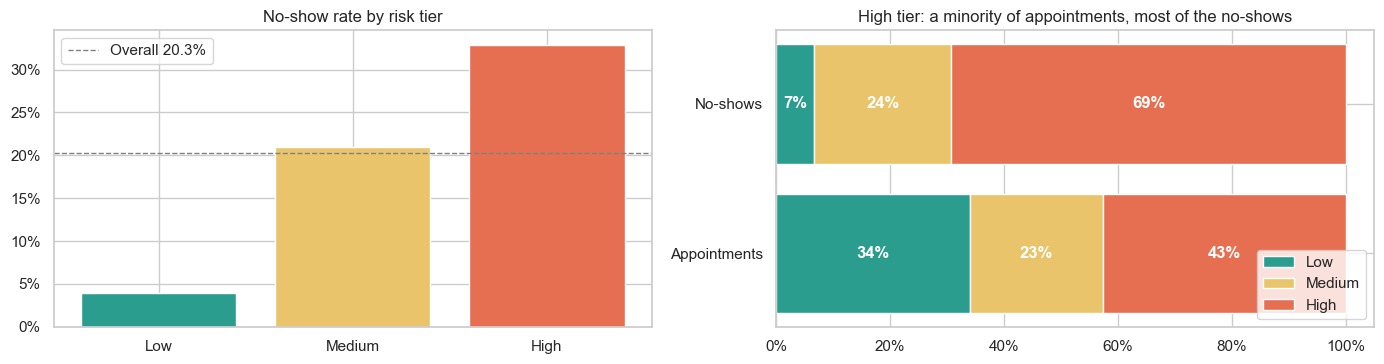

In [34]:
def assign_tier(lead_days, age, prior_no_shows):
    """No-show risk tier from the 3-level decision tree (section 15.3), using only booking-time data."""
    if lead_days == 0:
        return "High" if (prior_no_shows >= 2 and age <= 24) else "Low"
    if age <= 46:
        return "High"
    return "Medium" if prior_no_shows == 0 else "High"

final = seg_df.copy()
final["Tier"] = [assign_tier(l, a, p) for l, a, p in zip(final.LeadDays, final.Age, final.PrevNoShows)]

# Check the hand-written rules against the fitted tree's own leaf -> tier mapping
leaf_tier = {}
for leaf, conds in leaf_rules(tree, F15).items():
    rate = seg_tbl.loc[seg_tbl["segment rule"] == describe(conds), "tier"].iloc[0]
    leaf_tier[leaf] = rate
tree_tier = pd.Series(tree.apply(X15)).map(leaf_tier).astype(str).values
print(f"Rule function agrees with fitted tree on {(final.Tier.values == tree_tier).mean():.2%} of appointments")

tier_order = ["Low", "Medium", "High"]
summary16 = (final.groupby("Tier").agg(appointments=("NoShow", "size"), no_show_rate=("NoShow", "mean"),
                                       no_shows=("NoShow", "sum"))
                  .reindex(tier_order))
summary16["share_of_appointments"] = summary16.appointments / len(final)
summary16["share_of_no_shows"] = summary16.no_shows / final.NoShow.sum()
display(summary16.style.format({"appointments": "{:,.0f}", "no_shows": "{:,.0f}", "no_show_rate": "{:.1%}",
                                "share_of_appointments": "{:.0%}", "share_of_no_shows": "{:.0%}"}))

tier_colors = ["#2a9d8f", "#e9c46a", "#e76f51"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].bar(tier_order, summary16.no_show_rate, color=tier_colors)
axes[0].axhline(BASE, ls="--", color="gray", lw=1, label=f"Overall {BASE:.1%}"); axes[0].legend()
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("No-show rate by risk tier")
x = np.arange(2)
bottom = np.zeros(2)
for t, c in zip(tier_order, tier_colors):
    vals = summary16.loc[t, ["share_of_appointments", "share_of_no_shows"]].values.astype(float)
    axes[1].barh(x, vals, left=bottom, color=c, label=t)
    for xi, (b, v) in enumerate(zip(bottom, vals)):
        axes[1].text(b + v / 2, xi, f"{v:.0%}", ha="center", va="center", color="white", fontweight="bold")
    bottom += vals
axes[1].set_yticks(x); axes[1].set_yticklabels(["Appointments", "No-shows"])
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("High tier: a minority of appointments, most of the no-shows"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 16.2 Action plan by tier

| Tier | Action | Evidence |
|---|---|---|
| 🟢 **Low** | **No reminder needed.** Same-day patients already intend to come. | Same-day no-show rate is about 3–5% (section 5); same-day bookings never received SMS, yet attendance is near-perfect. |
| 🟡 **Medium** | **Standard SMS reminder.** | Reminders cut the odds of a no-show by about 26% for seniors at every lead time (section 13.2). |
| 🔴 **High** | **SMS plus a second touch:** a day-before reminder with a **confirm / reschedule** option, or a phone call for patients with prior no-shows. Treat these slots as **overbooking candidates**. | Reminders reduce no-shows most on routine bookings for kids (40% → 30%, 48% → 36%) and for prior missers (57% → 38%, sections 13.2–13.3). |

**Special cases within High**
- **Kids' routine and long-planned visits:** reminders work well here, so a second reminder is likely to pay off. Kids' bookings made **within a week** don't benefit from SMS (section 13.2), so effort is better spent elsewhere.
- **Repeat missers of any age:** a prior no-show raises the odds about 1.8x even after everything else is controlled for (section 14). A personal call is justified here.
- **Seniors still missing despite reminders:** test transport or caregiver outreach. The data can't measure this, but it fits the remaining no-show rate.

## 16.3 Shortening lead time, and measuring the impact

- **Shorten waits where possible.** Moving an appointment from 10+ days to under a week drops a younger patient from the 36% segment to the 29% segment. Same-day or next-day slots are the most reliable lever of all (OR about 7–13 for any lead time vs. same day, section 14).
- **Roll out as a test, not a blanket change.** Apply the tier actions to a random half of High-tier bookings first and compare no-show rates. This turns the observational findings here into causal evidence.
- **Track monthly:** no-show rate by tier, the share of no-shows falling in High, and reminder delivery rate (SMS coverage dropped to 52% in May 2016 in this data).

## 16.4 Limits and when to revisit

- This is observational data from about 6 weeks in one city (Vitória, Brazil, 2016). The tier rules should be **re-fit on local, current data** before use.
- The model's ceiling (AUC about 0.75) comes from **missing information**, not the method. **Start recording appointment type (routine / follow-up / urgent) and cancellations**, then re-fit the tree. Those fields are the most likely to sharpen the tiers and to test the "routine vs. need-driven" hypothesis directly.
- Keep the logistic model (section 14) for explaining effects and for finer-grained risk scores when needed.

**Bottom line:** three facts known at booking (**how far ahead, how old, and whether they've missed before**) sort patients into tiers that separate about 4% from about 30%+ no-show rates. Focusing reminders and follow-up on the High tier reaches about two-thirds of all no-shows by acting on fewer than half of appointments.